# Washington's summer of smoke, 2026, step by step

A walkthrough of how this forge3d animation is made, using the project's own scripts (`scripts/config.py`, `drape.py`, `render.py`, `finish.py`). The film shows hourly wildfire smoke and fire across Washington from 25 July to 10 September 2026, draped over Washington's terrain.

1. The canvas: Washington's terrain, and the trick that fits a whole state inside the viewer's camera
2. The data
3. From data to a colour drape for any moment
4. Frames, rendered and finished by the project's own pipeline

## Setup

Run `pixi run stills` once first so everything is downloaded into `data/`. Sections 1–3 need no renderer; section 4 opens forge3d's viewer (a GPU, or on Linux Mesa's software Vulkan under `xvfb-run`). It writes into `out/notebook/` and leaves the film in `out/` alone.

In [1]:
STILLS = "216,456,end"   # two hours in August and the final frame with the perimeters traced, as in `pixi run stills`
LITE = True              # lighter shadows and antialiasing (render.py --lite): much faster on a CPU

In [2]:
import json, math, sys, time
from pathlib import Path

import numpy as np
import rasterio
import matplotlib.pyplot as plt
from matplotlib.colors import LightSource
from PIL import Image
from IPython.display import Image as Show, display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "scripts" / "drape.py").exists())
sys.path.insert(0, str(ROOT / "scripts"))
import config, drape, render
import forge3d as f3d

%config InlineBackend.figure_formats = ["jpeg"]
%config InlineBackend.print_figure_kwargs = {"pil_kwargs": {"quality": 85}, "bbox_inches": "tight"}
plt.rcParams.update({"figure.dpi": 100, "font.size": 9})
print("forge3d", f3d.__version__)

forge3d 1.40.1


## 1. The canvas

All four Washington animations share one canvas: USGS 3DEP elevation resampled to 250 m in UTM zone 10N, from Portland to the Canadian border, with the state outline from Natural Earth. In 3D it's exaggerated 3.5× (the state is about 600 km wide, so true scale would be flat) and lightly smoothed so ridges read as ridges rather than needles.

**Fitting a state in the camera.** forge3d's viewer caps the camera distance at 50 km: plenty for one mountain, not for a whole state. So `render.scaled_dem` hands the viewer a copy of the DEM with every coordinate multiplied by a world scale (same pixels, smaller numbers), and the height exaggeration is scaled to match. The picture is identical and the camera stays inside its limit; `finish.py` uses the same scale to put the city labels in the right place.

DEM 2628 x 1659 at 250 m = 657 x 415 km, -3-4367 m
world scale 0.0685: the viewer sees a 45 km-wide state, with heights exaggerated 3.5 x 0.0685 = 0.2397
the viewer meshes it as a 1659 x 1659 grid: a vertex every 396 m east-west and 250 m north-south


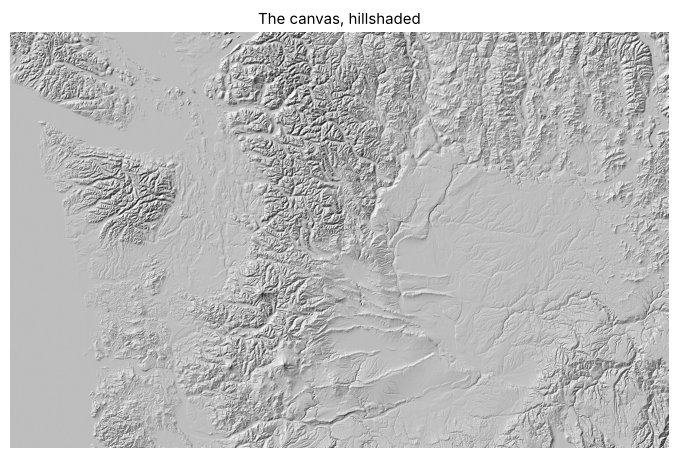

In [3]:
with rasterio.open(config.DEM) as src:
    dem = src.read(1); tf = src.transform
h, w = dem.shape
width_m = w * tf.a
s = render.WORLD_WIDTH_M / width_m
print(f"DEM {w} x {h} at {tf.a:g} m = {width_m / 1000:.0f} x {h * -tf.e / 1000:.0f} km, {dem.min():.0f}-{dem.max():.0f} m")
print(f"world scale {s:.4f}: the viewer sees a {render.WORLD_WIDTH_M / 1000:.0f} km-wide state, "
      f"with heights exaggerated {config.EXAGGERATION} x {s:.4f} = {config.EXAGGERATION * s:.4f}")
n = min(2048, h, w)      # the viewer's log: a square mesh, at most 2048 a side and no more than the DEM's shorter side
print(f"the viewer meshes it as a {n} x {n} grid: a vertex every {width_m / (n - 1):.0f} m east-west and "
      f"{h * -tf.e / (n - 1):.0f} m north-south")
fig, ax = plt.subplots(figsize=(10, 5.4))
ax.imshow(LightSource(azdeg=315, altdeg=35).hillshade(np.where(dem <= 0.5, 0, dem), vert_exag=3, dx=tf.a, dy=-tf.e), cmap="gray")
ax.set_title("The canvas, hillshaded"); ax.axis("off"); plt.show()

## 2. The data: smoke and fire

- **Smoke** is near-surface smoke (MASSDEN, 8 m above ground) from NOAA's **HRRR-Smoke** model on its 3 km grid, every hour: the 1-hour forecast from the previous run, byte-range downloaded from NOAA's open-data bucket on AWS so only the smoke field comes down.
- **Fire detections** are NASA FIRMS VIIRS hotspots (375 m, from three satellites).
- **Perimeters** are NIFC's WFIGS interagency fire perimeters.

HRRR-Smoke is a model driven by satellite fire observations, not a network of monitors, so it's good at where the smoke goes and roughly how thick it is, but a city's number won't match its monitor hour for hour.

HRRR-Smoke: 1152 hours on a 234 x 281 grid, 2026-07-25T00:00 to 2026-09-10T23:00 UTC


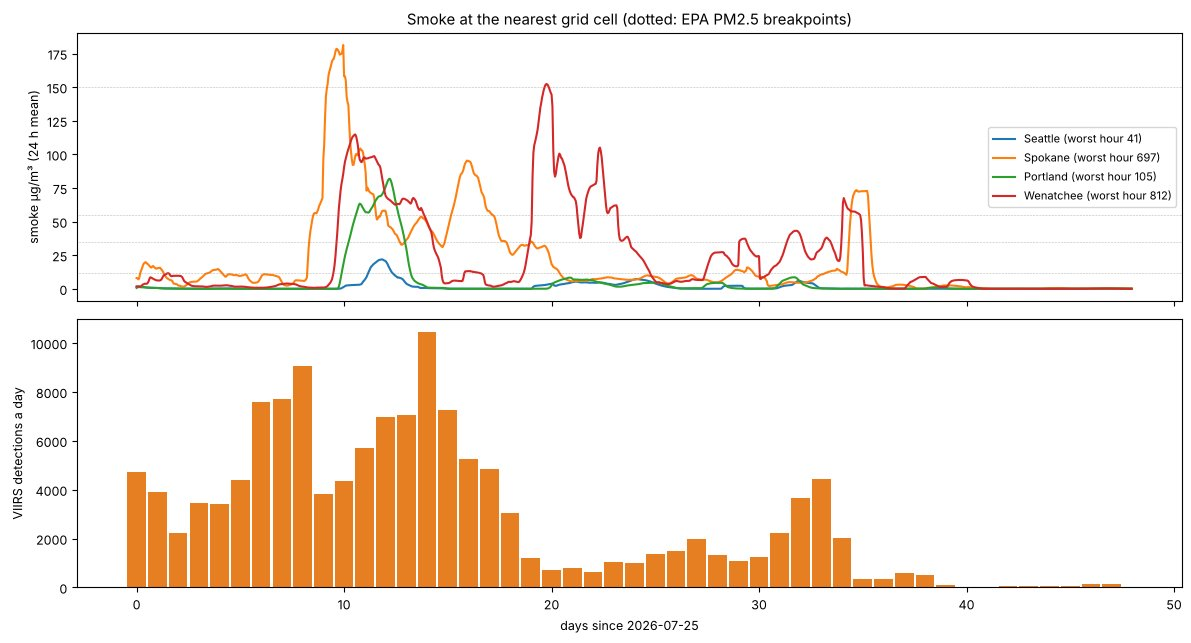

133,866 VIIRS fire detections in the box


In [4]:
d = np.load(config.SMOKE)
glat, glon, sm, tu = d["lat"], d["lon"], d["smoke"], d["times_utc"]
print(f"HRRR-Smoke: {sm.shape[0]} hours on a {sm.shape[1]} x {sm.shape[2]} grid, {tu[0]} to {tu[-1]} UTC")
def at(c):
    k = np.argmin((glat - c.lat) ** 2 + ((glon - c.lon) * np.cos(np.radians(c.lat))) ** 2)
    return sm[:, k // sm.shape[2], k % sm.shape[2]].astype(np.float32)
import pandas as pd
fig, axs = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True)
days = np.arange(sm.shape[0]) / 24
for c in config.CITIES[:4]:
    s = at(c); axs[0].plot(days, pd.Series(s).rolling(24, min_periods=1).mean(), label=f"{c.name} (worst hour {s.max():.0f})")
for v, lab in config.SMOKE_TICKS[1:5]:
    axs[0].axhline(v, color="grey", lw=0.4, ls=":")
axs[0].set_ylabel("smoke µg/m³ (24 h mean)"); axs[0].legend(fontsize=8); axs[0].set_title("Smoke at the nearest grid cell (dotted: EPA PM2.5 breakpoints)")
fd = pd.read_csv(config.DETECTIONS)
dcol = "acq_date" if "acq_date" in fd else fd.columns[0]
per_day = pd.to_datetime(fd[dcol]).dt.floor("D").value_counts().sort_index()
x = (per_day.index - pd.Timestamp(str(tu[0])[:10])).days
axs[1].bar(x, per_day.values, color="#e67e22", width=0.9); axs[1].set_ylabel("VIIRS detections a day")
axs[1].set_xlabel(f"days since {str(tu[0])[:10]}")
plt.tight_layout(); plt.show()
print(f"{len(fd):,} VIIRS fire detections in the box")

## 3. How the smoke is drawn

Smoke draped on the terrain looks like paint on the hills, so each frame is rendered **twice**:

1. **The land:** terrain, burn scars (each satellite detection glows orange for 12 hours, then leaves a charcoal scar, so fires grow night by night) and active fires.
2. **The smoke alone**, at half size and colour-coded: red for smoke, blue for none. The viewer's lighting scales red and blue by the same factor, so their *ratio* still gives the smoke amount after shading.

`finish.py` reads that ratio back and lays the smoke over the land as an unshaded veil, pale grey when thin and brown when heavy, then puts the fires back on top with a soft glow. Here are the two drapes for one hour:

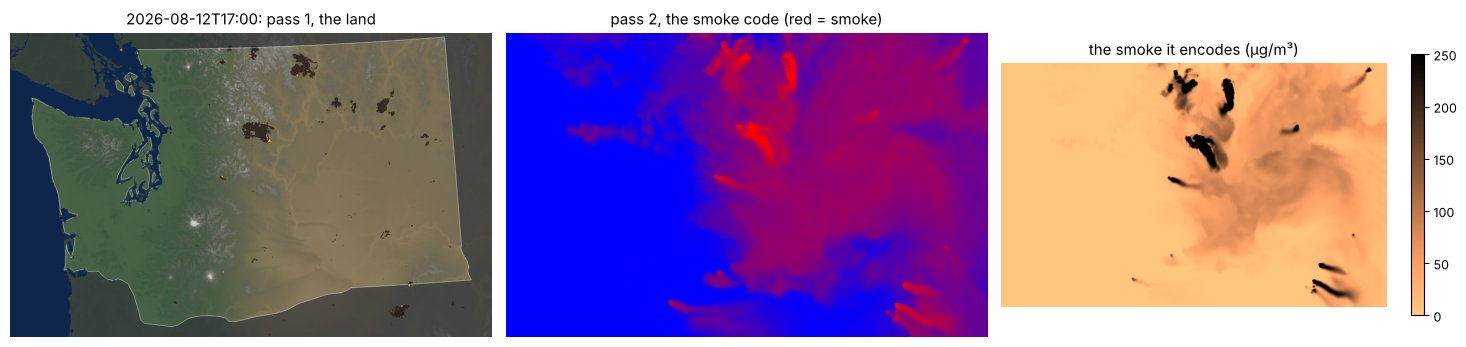

In [5]:
dr = drape.Drape(water_key=False)
H = 456
land, c = dr.image(H, smoke=False)
code_img = drape.Drape.smoke_code(c)
fig, axs = plt.subplots(1, 3, figsize=(15, 4))
axs[0].imshow(land); axs[0].set_title(f"{dr.time_label(H)}: pass 1, the land")
axs[1].imshow(code_img); axs[1].set_title("pass 2, the smoke code (red = smoke)")
im = axs[2].imshow(c, cmap="copper_r", vmin=0, vmax=config.SMOKE_MAX); axs[2].set_title("the smoke it encodes (µg/m³)")
plt.colorbar(im, ax=axs[2], shrink=0.7)
for a in axs: a.axis("off")
plt.tight_layout(); plt.show()

## 4. Frames

The camera sits south of the state looking north, 45° down, and swings slowly round toward the south-west over the course of the film. Each frame is two snapshots from the same camera: the land drape, then the smoke code. Both use forge3d's preserve-colours mode. `finish.py` then paints a dark sky, swaps the key-green water for deep blue, and adds the title, the clock and timeline, the city readings (projected with the viewer's own camera maths and faded out if they'd collide) and the legend.

Rather than re-implement any of that here, this runs the project's own `render.py --stills` with its output pointed at `out/notebook/`.

In [6]:
nb_out = config.OUT / "notebook"
config.OUT = nb_out                                        # viewer.log and work files
config.out_dir = lambda fmt: nb_out                        # frames/ and final/
config.video_path = lambda fmt: nb_out / "stills.mp4"      # leaves the film alone
nb_out.mkdir(parents=True, exist_ok=True)
argv = ["render.py", "--stills", STILLS] + (["--lite"] if LITE else [])
import contextlib, io
t0 = time.time()
log = io.StringIO()
old, sys.argv = sys.argv, argv
try:
    with contextlib.redirect_stdout(log):
        render.main()
finally:
    sys.argv = old
for line in log.getvalue().replace("\r", "\n").splitlines():
    if line.strip() and not line.startswith(("Video", "  finishing")) and "frame " not in line:
        print(line.strip())
finals = sorted((nb_out / "final").glob("frame_*.png"))
print(f"\n{len(finals)} finished frames in {time.time() - t0:.0f} s")

Preparing the land, fires and smoke...
Previewing 3 frames (1151 hours at 1 frames an hour)...
Finishing 3 frames on 1 worker(s)...

3 finished frames in 112 s


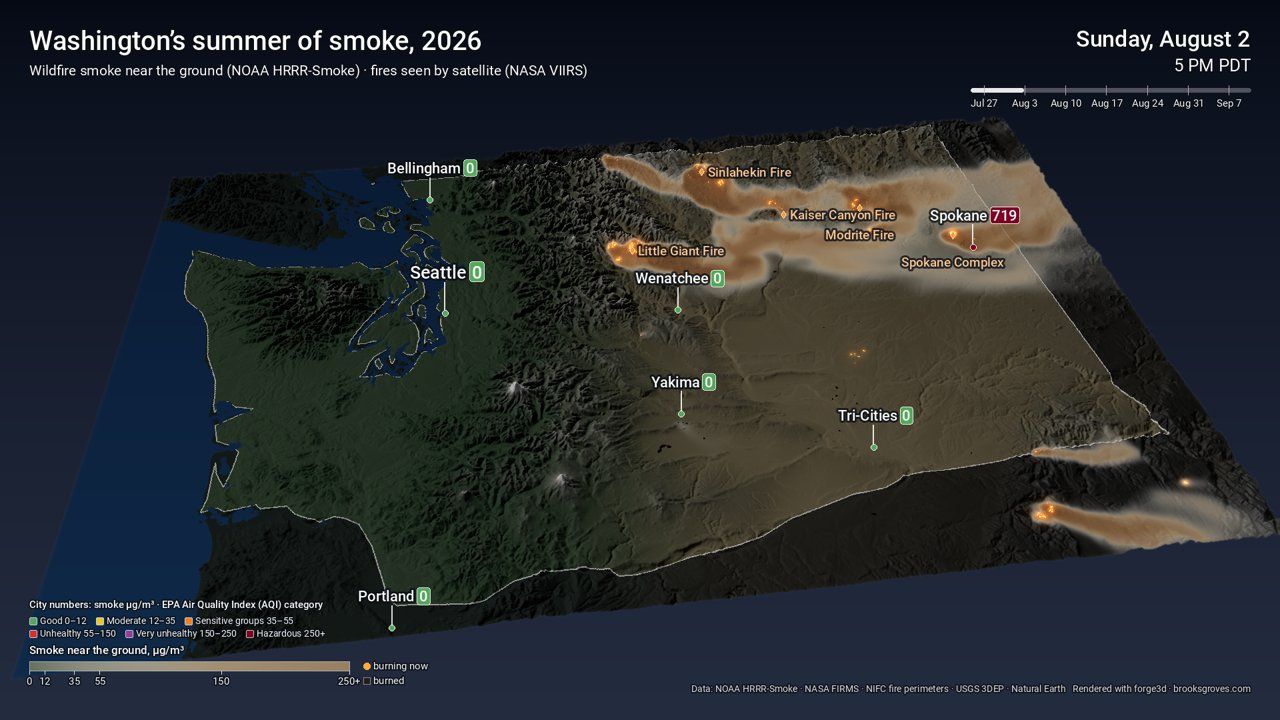

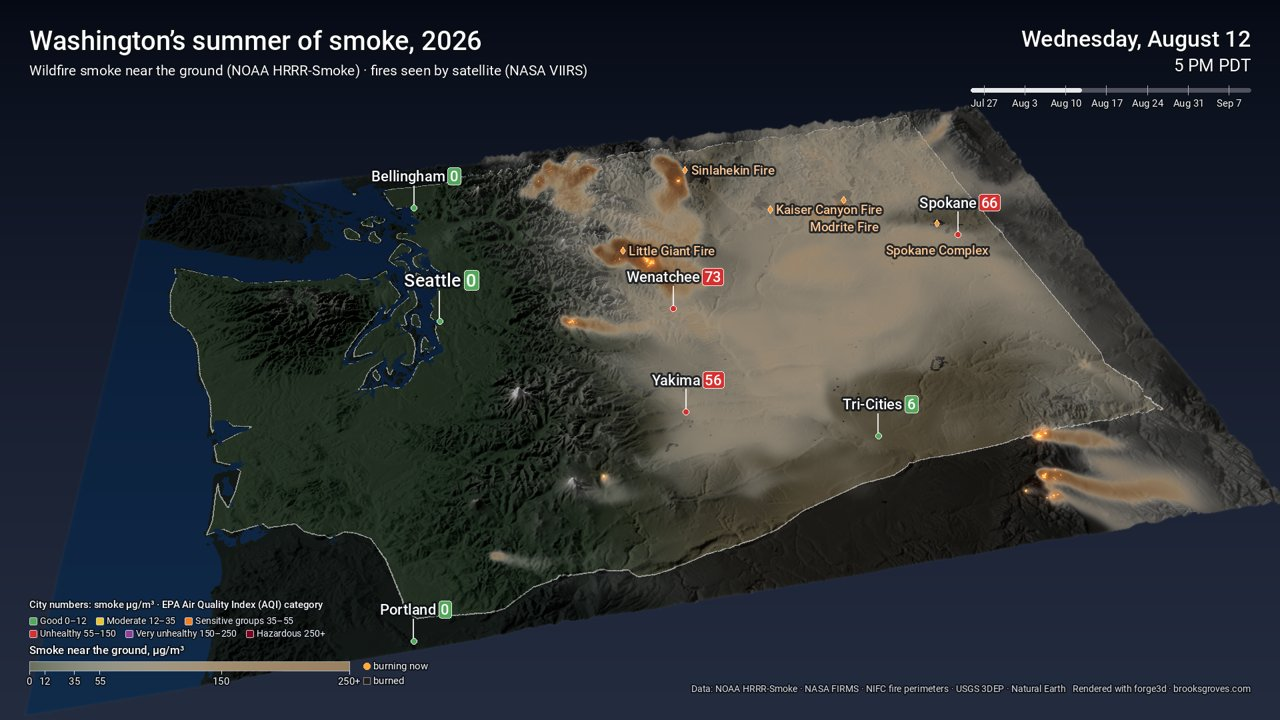

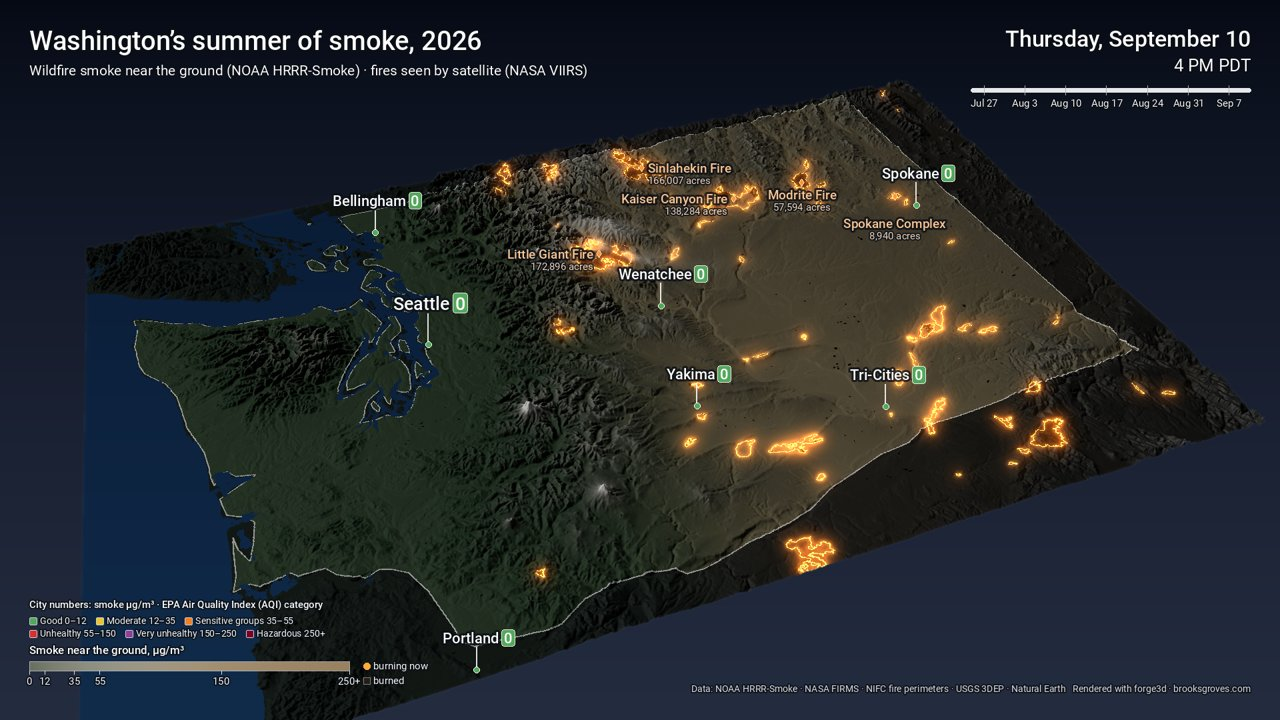

In [7]:
for p in finals:
    im = Image.open(p).convert("RGB")
    im.thumbnail((1280, 1280))
    q = p.with_suffix(".jpg"); im.save(q, quality=85)
    display(Show(filename=str(q), width=960))

## Caveats

- HRRR-Smoke is a model, not monitors; city readings won't match their air-quality monitors hour for hour.
- The PM2.5 colours on the city readings use the EPA's 24-hour category breakpoints as a familiar reference; the readings themselves are hourly smoke only.
- VIIRS sees each spot about twice a day and can miss fire under thick smoke or cloud, so growth is stepwise and small fires can be missed.

The film is `pixi run render` (16:9), with `render-square` and `render-portrait` cuts for social.

Data: NOAA HRRR-Smoke · NASA FIRMS VIIRS · NIFC WFIGS · USGS 3DEP · Natural Earth. Rendering: [forge3d](https://github.com/milos-agathon/forge3d) by Milos Popovic, whose wildfire smoke and temperature animations inspired these.